# StudentPulse Analytics

### Discovering Student Lifestyle Patterns and Academic Performance Through Data Science

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

**Techniques:** Exploratory Data Analysis, Statistical Analysis, Correlation Analysis, Data Visualization, K-Means Clustering

## Executive Summary

**Question:** How do daily lifestyle habits relate to academic performance and stress among 2,000 students?

**Approach:** Data validation, exploratory analysis, correlation and statistical tests, K-Means clustering (k = 4) and a linear regression model.

**Key findings**
- **Study time is the dominant factor.** Study hours have a strong correlation with GPA (r = 0.73). A simple model using daily lifestyle hours explains about 55% of GPA variation on unseen data (test R² = 0.55, average error ≈ 0.16 GPA points), and study hours account for almost all of that.
- **Time is a trade-off.** Every student's tracked day sums to exactly 24 hours, so more time on one activity means less on others. This explains why physical activity shows a negative raw correlation with GPA (r = -0.34) while sleep, social and extracurricular time show almost none.
- **The stress-GPA pattern is explained by study time.** High-stress students have the highest GPA (3.26 vs 2.82 for low stress), but they also study far more (8.4 vs 5.5 hours per day). Within similar study-hour bands, GPA barely differs across stress levels.
- **Four lifestyle profiles** were identified. "Focused Achievers" have the highest average GPA (3.30) and "Rested Socialisers" the lowest (2.92). GPA differs significantly across clusters (ANOVA p < 0.001, eta-squared = 0.25), although the clusters overlap (silhouette ≈ 0.22).

**Takeaway:** Study time is the main lever for GPA in this dataset, and high stress here largely reflects heavy workload rather than weaker performance. Support programmes could focus on helping high-workload students study effectively while managing stress.

## Project Objectives

The main objectives of StudentPulse Analytics are:

- To explore the lifestyle characteristics of students using descriptive statistics.
- To examine the relationship between daily lifestyle habits and GPA.
- To analyze how stress levels differ in relation to lifestyle characteristics.
- To visualize important patterns and relationships within the dataset.
- To identify distinct student lifestyle profiles using K-Means clustering.
- To compare academic performance across the identified lifestyle clusters.
- To demonstrate how statistical analysis and machine learning can be applied to real-world student data.

## Dataset Description

The Student Lifestyle Dataset contains information about students' daily lifestyle habits and academic performance.

The dataset includes variables related to:

- **Student ID** – Unique identifier for each student.
- **Study Hours Per Day** – Number of hours spent studying each day.
- **Sleep Hours Per Day** – Number of hours spent sleeping each day.
- **Social Hours Per Day** – Number of hours spent on social activities each day.
- **Physical Activity Hours Per Day** – Number of hours spent on physical activities each day.
- **Extracurricular Hours Per Day** – Number of hours spent on extracurricular activities each day.
- **GPA** – Grade Point Average representing academic performance.
- **Stress Level** – Reported stress category of the student.

The dataset contains **2,000 student records**, allowing patterns and relationships between lifestyle habits and academic performance to be explored.

### Dataset Analysis Approach

The dataset is analyzed using a combination of:

1. **Descriptive Statistics** to understand the distribution of individual variables.
2. **Exploratory Data Analysis (EDA)** to identify patterns and trends.
3. **Correlation Analysis** to examine relationships between lifestyle variables and GPA.
4. **Data Visualization** to communicate important findings.
5. **K-Means Clustering** to discover distinct student lifestyle profiles.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

C = {"bg": "#FAF6F1", "sand": "#E9DCCB", "beige": "#D4B8A0", "taupe": "#A68A7B",
     "mocha": "#7F5539", "cocoa": "#4A3728", "rose": "#C99A93", "sage": "#8F9E83", "clay": "#B9795E"}
STRESS_ORDER = ["Low", "Moderate", "High"]
STRESS_COLORS = {"Low": C["sage"], "Moderate": C["beige"], "High": C["clay"]}
CLUSTER_COLORS = [C["taupe"], C["sage"], C["mocha"], C["rose"]]
NUDE_DIVERGING = LinearSegmentedColormap.from_list(
    "nude_div", [C["rose"], "#EADBD0", C["bg"], C["beige"], C["mocha"]])

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({
    "figure.facecolor": C["bg"], "axes.facecolor": C["bg"], "savefig.facecolor": C["bg"],
    "axes.edgecolor": C["sand"], "grid.color": C["sand"], "grid.linewidth": 0.8,
    "text.color": C["cocoa"], "axes.labelcolor": C["cocoa"],
    "xtick.color": C["cocoa"], "ytick.color": C["cocoa"],
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlepad": 14,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "legend.frameon": False,
})
os.makedirs("images", exist_ok=True)   # charts get saved here for GitHub


def finish(ax, title, xlabel=None, ylabel=None, name=None):
    ax.set_title(title, loc="left")
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    plt.tight_layout()
    if name:
        plt.savefig(f"images/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def add_bar_labels(ax, fmt="{:.2f}"):
    for p in ax.patches:
        ax.annotate(fmt.format(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=11, fontweight="bold",
                    color=C["cocoa"], xytext=(0, 4), textcoords="offset points")

## 1. Importing Libraries and Loading the Dataset

The first step is to import the Python libraries required for data analysis and visualization. The dataset is then loaded into a Pandas DataFrame so that it can be explored and analyzed.

In [2]:
df = pd.read_csv("student_lifestyle_dataset.csv")

In [3]:
df.head()

,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


In [4]:
df.shape

(2000, 8)

**Dataset Overview**

The dataset contains **2,000 student records and 8 variables**, providing a foundation for exploring the relationship between student lifestyle patterns, academic performance and stress levels.

In [5]:
df.columns# TELLS US ALL THE VARIABLES IN THE DATASET

Index(['Student_ID', 'Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day',
       'Sleep_Hours_Per_Day', 'Social_Hours_Per_Day',
       'Physical_Activity_Hours_Per_Day', 'GPA', 'Stress_Level'],
      dtype='object')

**Understanding the Variables**

The dataset captures five key lifestyle dimensions alongside academic performance and reported stress levels. `Student_ID` serves as a unique identifier, while the remaining variables support the analysis of student lifestyle patterns and their association with GPA.

In [6]:
df.dtypes#

Student_ID                           int64
Study_Hours_Per_Day                float64
Extracurricular_Hours_Per_Day      float64
Sleep_Hours_Per_Day                float64
Social_Hours_Per_Day               float64
Physical_Activity_Hours_Per_Day    float64
GPA                                float64
Stress_Level                        object
dtype: object

**Data Types Assessment**

The dataset contains numerical variables (`int64` and `float64`) for student identifiers, lifestyle measurements and GPA, while `Stress_Level` is stored as an object (categorical) variable. These formats are suitable for the planned statistical analysis and visualisation.

In [7]:
df.isnull().sum()#finds out the missing values

Student_ID                         0
Study_Hours_Per_Day                0
Extracurricular_Hours_Per_Day      0
Sleep_Hours_Per_Day                0
Social_Hours_Per_Day               0
Physical_Activity_Hours_Per_Day    0
GPA                                0
Stress_Level                       0
dtype: int64

**Missing Value Assessment**

No missing values were identified across the 2,000 records, indicating a complete dataset with no missing entries requiring imputation.

In [8]:
data_dictionary = pd.DataFrame({
    "Variable_Name": df.columns,
    "Variable_Type": df.dtypes.astype(str),
    "Missing_Values": df.isnull().sum().values,
    "Unique_Values": df.nunique().values
})

data_dictionary

,Variable_Name,Variable_Type,Missing_Values,Unique_Values
Student_ID,Student_ID,int64,0,2000
Study_Hours_Per_Day,Study_Hours_Per_Day,float64,0,51
Extracurricular_Hours_Per_Day,Extracurricular_Hours_Per_Day,float64,0,41
Sleep_Hours_Per_Day,Sleep_Hours_Per_Day,float64,0,51
Social_Hours_Per_Day,Social_Hours_Per_Day,float64,0,61
Physical_Activity_Hours_Per_Day,Physical_Activity_Hours_Per_Day,float64,0,118
GPA,GPA,float64,0,158
Stress_Level,Stress_Level,object,0,3


**Data Dictionary Overview**

The data dictionary provides a structured reference to all eight variables, documenting their definitions, data types and observed values. This establishes clarity and consistency for subsequent analysis.

In [9]:
# Find minimum and maximum values for each variable

numeric_columns = df.select_dtypes(include='number').columns

min_values = df[numeric_columns].min()
max_values = df[numeric_columns].max()

print("Minimum Values:")
print(min_values)

print("\nMaximum Values:")
print(max_values)

Minimum Values:
Student_ID                         1.00
Study_Hours_Per_Day                5.00
Extracurricular_Hours_Per_Day      0.00
Sleep_Hours_Per_Day                5.00
Social_Hours_Per_Day               0.00
Physical_Activity_Hours_Per_Day    0.00
GPA                                2.24
dtype: float64

Maximum Values:
Student_ID                         2000.0
Study_Hours_Per_Day                  10.0
Extracurricular_Hours_Per_Day         4.0
Sleep_Hours_Per_Day                  10.0
Social_Hours_Per_Day                  6.0
Physical_Activity_Hours_Per_Day      13.0
GPA                                   4.0
dtype: float64


**Variable Range Assessment**

The observed ranges provide an overview of the distribution and scale of each numerical variable. These values establish a baseline for identifying unusual observations and understanding the dataset before further analysis.

In [10]:
df["Stress_Level"].value_counts()

Stress_Level
High        1029
Moderate     674
Low          297
Name: count, dtype: int64

**Stress Level Distribution**

The dataset is dominated by students reporting **high stress (51.45%)**, followed by moderate (33.70%) and low stress (14.85%). This distribution provides an important context for examining the relationship between stress, lifestyle patterns and academic performance.

In [11]:
# Create a professional data dictionary

data_dictionary = pd.DataFrame({
    "Variable_Name": df.columns,
    "Variable_Type": [
        "Identifier",
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Numerical",
        "Categorical"
    ],
    "Meaning": [
        "Unique identifier assigned to each student",
        "Number of hours spent studying per day",
        "Number of hours spent on extracurricular activities per day",
        "Number of hours spent sleeping per day",
        "Number of hours spent on social activities per day",
        "Number of hours spent on physical activity per day",
        "Grade Point Average of the student",
        "Reported stress category of the student"
    ],
    "Missing_Values": df.isnull().sum().values,
    "Minimum": [
        "-",
        df["Study_Hours_Per_Day"].min(),
        df["Extracurricular_Hours_Per_Day"].min(),
        df["Sleep_Hours_Per_Day"].min(),
        df["Social_Hours_Per_Day"].min(),
        df["Physical_Activity_Hours_Per_Day"].min(),
        df["GPA"].min(),
        "-"
    ],
    "Maximum": [
        "-",
        df["Study_Hours_Per_Day"].max(),
        df["Extracurricular_Hours_Per_Day"].max(),
        df["Sleep_Hours_Per_Day"].max(),
        df["Social_Hours_Per_Day"].max(),
        df["Physical_Activity_Hours_Per_Day"].max(),
        df["GPA"].max(),
        "-"
    ],
    "Unique_Values": df.nunique().values
})

data_dictionary

,Variable_Name,Variable_Type,Meaning,Missing_Values,Minimum,Maximum,Unique_Values
0,Student_ID,Identifier,Unique identifier assigned to each student,0,-,-,2000
1,Study_Hours_Per_Day,Numerical,Number of hours spent studying per day,0,5.0,10.0,51
2,Extracurricular_Hours_Per_Day,Numerical,Number of hours spent on extracurricular activ...,0,0.0,4.0,41
3,Sleep_Hours_Per_Day,Numerical,Number of hours spent sleeping per day,0,5.0,10.0,51
4,Social_Hours_Per_Day,Numerical,Number of hours spent on social activities per...,0,0.0,6.0,61
5,Physical_Activity_Hours_Per_Day,Numerical,Number of hours spent on physical activity per...,0,0.0,13.0,118
6,GPA,Numerical,Grade Point Average of the student,0,2.24,4.0,158
7,Stress_Level,Categorical,Reported stress category of the student,0,-,-,3


**Data Dictionary**

A structured reference to the dataset's eight variables, documenting their definitions, data types, missing values and observed ranges to ensure clarity throughout the analysis.

In [12]:
# Calculate total daily lifestyle hours and avoid floating-point precision errors

lifestyle_columns = [
    "Study_Hours_Per_Day",
    "Extracurricular_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Social_Hours_Per_Day",
    "Physical_Activity_Hours_Per_Day"
]

df["Total_Tracked_Hours"] = (
    df[lifestyle_columns].sum(axis=1).round(2)
)

# Display the summary of total daily hours.
df["Total_Tracked_Hours"].describe()

count    2000.0
mean       24.0
std         0.0
min        24.0
25%        24.0
50%        24.0
75%        24.0
max        24.0
Name: Total_Tracked_Hours, dtype: float64

**Daily Time Consistency Analysis**

A consistency check examines whether the combined daily lifestyle hours exceed the 24-hour limit. This helps identify potential structural inconsistencies in the recorded data.

In [13]:
# Identify students whose total tracked hours genuinely exceed 24.

students_over_24 = df[df["Total_Tracked_Hours"] > 24]

students_over_24

,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level,Total_Tracked_Hours


**Daily Time Consistency Analysis**

All 2,000 records report a combined lifestyle duration of **24.0 hours per day**. No records exceed the 24-hour limit after accounting for floating-point precision. This reveals a consistent structural constraint in the dataset.

In [14]:
# Check whether Student_ID contains duplicates

df["Student_ID"].duplicated().sum()

np.int64(0)

**Duplicate Record Assessment**

No duplicate Student IDs were identified, confirming that each student record has a unique identifier.

In [15]:
# Check for completely duplicated records
 
df.duplicated().sum()

np.int64(0)

In [16]:
df["Study_Hours_Per_Day"].describe()

count    2000.000000
mean        7.475800
std         1.423888
min         5.000000
25%         6.300000
50%         7.400000
75%         8.700000
max        10.000000
Name: Study_Hours_Per_Day, dtype: float64

**Study Hours — Descriptive Statistics**

Students spend an average of **7.48 hours per day** studying, with a median of 7.4 hours. Study duration ranges from 5 to 10 hours, while the standard deviation of 1.42 indicates relatively moderate variation across observations.

The close alignment between the mean and median suggests a fairly balanced distribution of study hours.

**Distribution of Daily Study Hours**

The distribution shows how students allocate their daily study time. Study hours are concentrated around the average of **7.48 hours**, with most observations falling between 6.3 and 8.7 hours.

This suggests relatively consistent study patterns across the dataset.

In [17]:
import pandas as pd

df = pd.read_csv("student_lifestyle_dataset.csv")

df.head()

,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


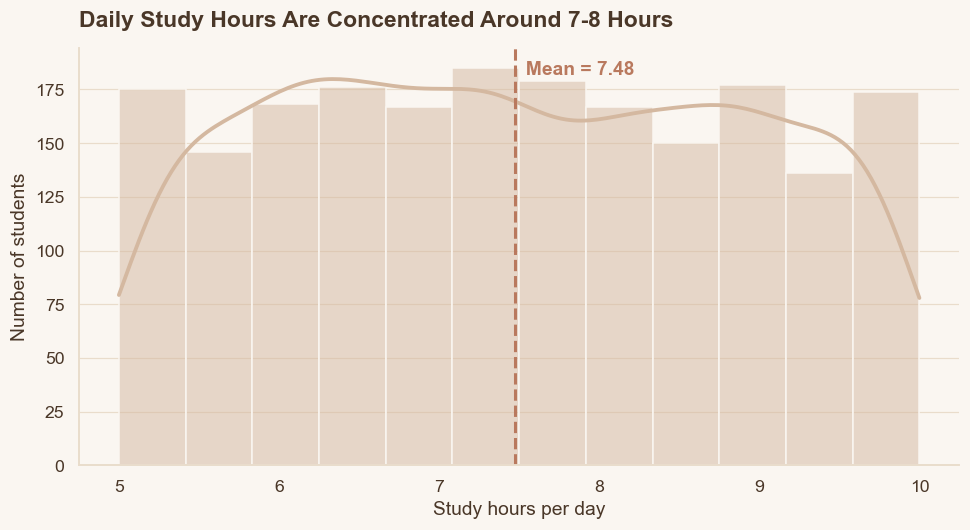

In [18]:
def nice_hist(col, title, xlabel, name):
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.histplot(df[col], bins=12, kde=True, color=C["beige"], edgecolor=C["bg"],
                 line_kws={"color": C["mocha"], "lw": 2.5}, ax=ax)
    m = df[col].mean()
    ax.axvline(m, color=C["clay"], ls="--", lw=2)
    ax.text(m, ax.get_ylim()[1] * 0.97, f"  Mean = {m:.2f}", color=C["clay"],
            fontweight="bold", va="top")
    ax.grid(axis="x", visible=False)
    finish(ax, title, xlabel, "Number of students", name)

nice_hist("Study_Hours_Per_Day", "Daily Study Hours Are Concentrated Around 7-8 Hours",
          "Study hours per day", "01_study_hours_distribution")

In [19]:
df["GPA"].describe()

count    2000.000000
mean        3.115960
std         0.298674
min         2.240000
25%         2.900000
50%         3.110000
75%         3.330000
max         4.000000
Name: GPA, dtype: float64

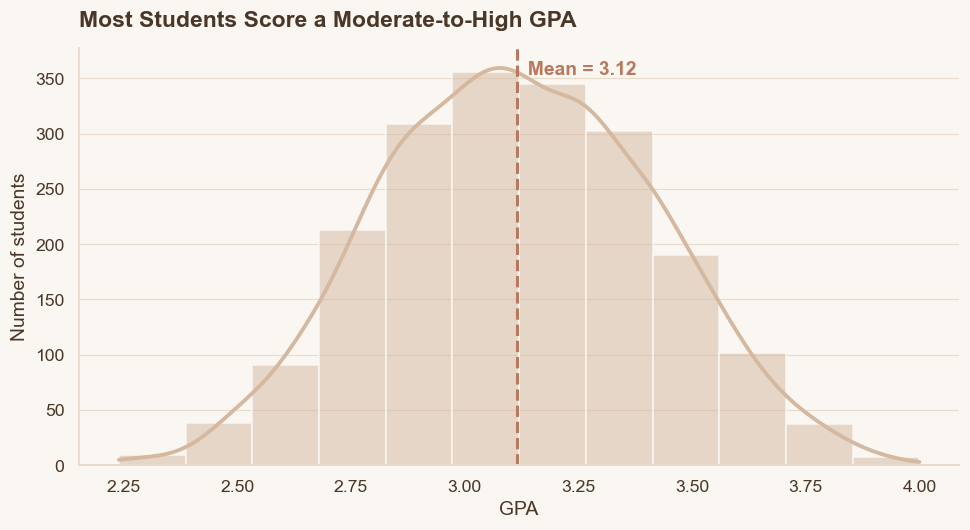

In [20]:
import matplotlib.pyplot as plt

nice_hist("GPA", "Most Students Score a Moderate-to-High GPA", "GPA", "02_gpa_distribution")

**Distribution of Academic Performance (GPA)**

The GPA distribution provides an overview of academic performance across the 2,000 students. Scores range from **2.24 to 4.00**, with an average GPA of approximately **3.12**, indicating that the dataset is centred around a moderate-to-high academic performance range.

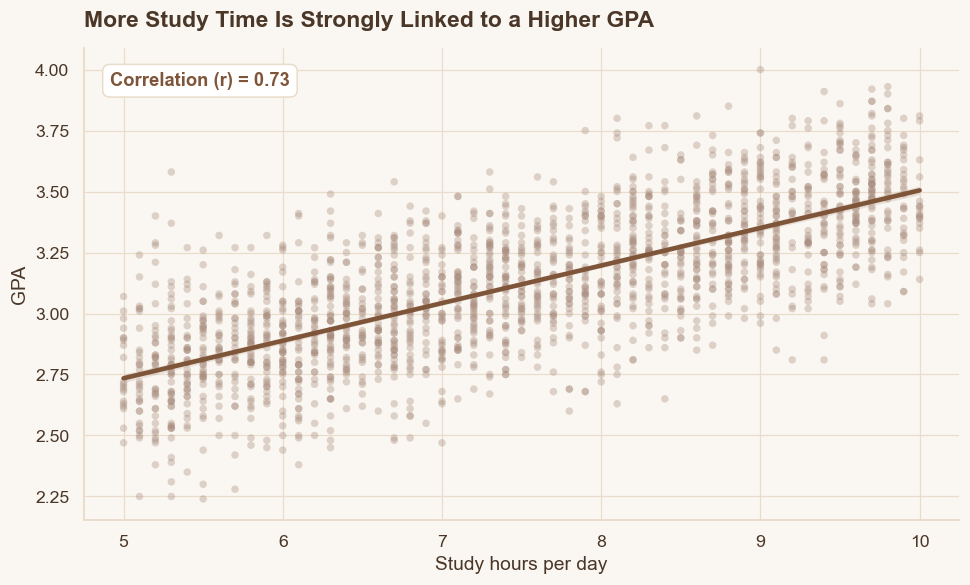

In [21]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.regplot(data=df, x="Study_Hours_Per_Day", y="GPA",
            scatter_kws={"alpha": 0.35, "s": 24, "color": C["taupe"], "edgecolor": "none"},
            line_kws={"color": C["mocha"], "lw": 3}, ax=ax)
r = df["Study_Hours_Per_Day"].corr(df["GPA"])
ax.text(0.03, 0.95, f"Correlation (r) = {r:.2f}", transform=ax.transAxes, va="top",
        fontsize=12, fontweight="bold", color=C["mocha"],
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=C["sand"]))
finish(ax, "More Study Time Is Strongly Linked to a Higher GPA",
       "Study hours per day", "GPA", "03_study_vs_gpa")

In [22]:
# We calculate correlation to measure the strength and direction of the relationship between study hours and GPA.

correlation = df["Study_Hours_Per_Day"].corr(df["GPA"])

# Display the correlation value.
print("Correlation between Study Hours and GPA:", correlation)

Correlation between Study Hours and GPA: 0.7344679806560519


## Interpretation: Study Hours and GPA

The correlation between Study Hours Per Day and GPA is **0.7345**.

This indicates a strong positive relationship between the two variables. In this dataset, students who spend more time studying tend to have higher GPAs.

However, correlation does not prove that studying more directly causes a higher GPA, as other factors may also influence academic performance.

In [23]:
# We calculate the average GPA for each stress level to compare academic performance across stress categories.

stress_gpa = df.groupby("Stress_Level")["GPA"].mean()

# Display the average GPA for each stress level.
print(stress_gpa)

Stress_Level
High        3.261973
Low         2.816869
Moderate    3.024837
Name: GPA, dtype: float64


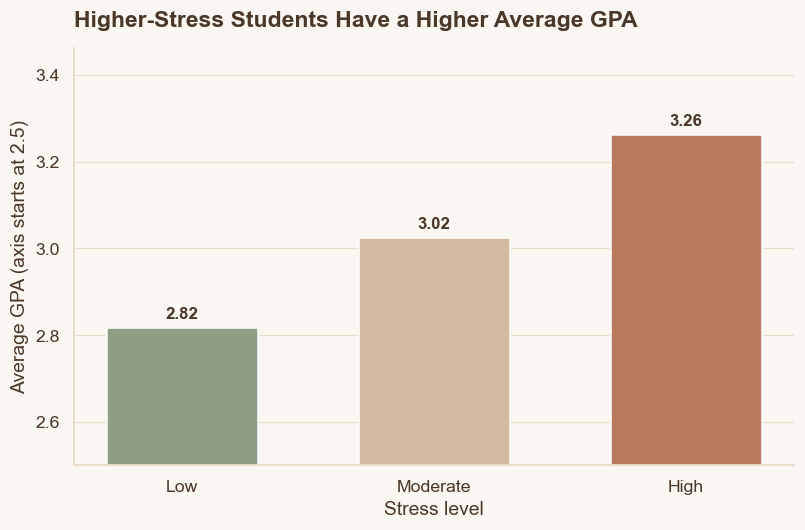

In [24]:
stress_gpa = df.groupby("Stress_Level")["GPA"].mean().reindex(STRESS_ORDER)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.bar(stress_gpa.index, stress_gpa.values,
       color=[STRESS_COLORS[s] for s in stress_gpa.index], width=0.6)
ax.set_ylim(2.5, stress_gpa.max() + 0.2)
add_bar_labels(ax)
ax.grid(axis="x", visible=False)
finish(ax, "Higher-Stress Students Have a Higher Average GPA", "Stress level",
       "Average GPA (axis starts at 2.5)", "04_gpa_by_stress")

## Interpretation: Stress Level and GPA

The average GPA differs across the three stress-level groups.

Students classified as having **high stress** have the highest average GPA (**3.26**), followed by students with **moderate stress** (**3.02**). Students with **low stress** have the lowest average GPA (**2.82**).

This is an unexpected pattern because higher stress does not correspond to lower GPA in this dataset. However, this result shows an **association rather than causation**. We cannot conclude that high stress causes higher GPA because other factors may influence academic performance.

In [25]:
# We calculate the average lifestyle hours for each stress level
# to understand how students with different stress levels spend their day.

lifestyle_by_stress = df.groupby("Stress_Level")[
    [
        "Study_Hours_Per_Day",
        "Sleep_Hours_Per_Day",
        "Social_Hours_Per_Day",
        "Physical_Activity_Hours_Per_Day",
        "Extracurricular_Hours_Per_Day"
    ]
].mean()

# Display the comparison table.
lifestyle_by_stress

,Study_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,Extracurricular_Hours_Per_Day
Stress_Level,,,,,
High,8.385034,7.046453,2.627794,3.960933,1.979786
Low,5.474411,8.063973,2.890909,5.581818,1.988889
Moderate,6.969585,7.947626,2.739614,4.336795,2.006380


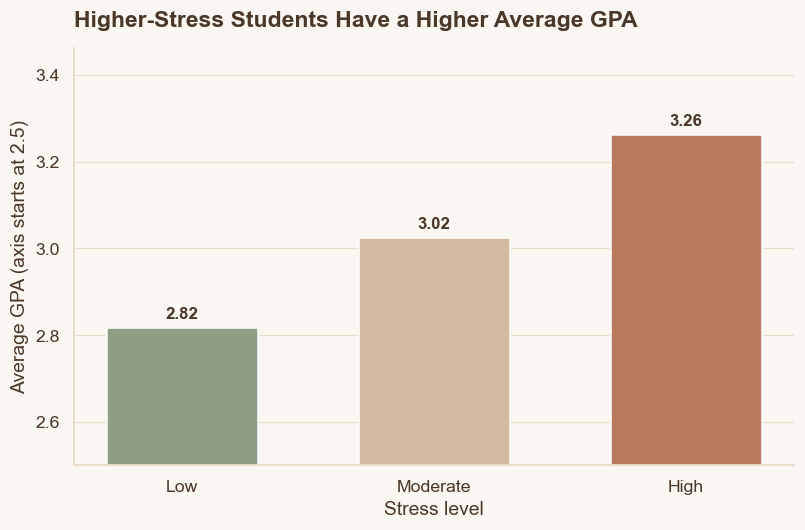

In [26]:
# We create a bar chart to compare average study time across different stress levels.
# This helps us visually examine whether study time differs between stress groups.

stress_gpa = df.groupby("Stress_Level")["GPA"].mean().reindex(STRESS_ORDER)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.bar(stress_gpa.index, stress_gpa.values,
       color=[STRESS_COLORS[s] for s in stress_gpa.index], width=0.6)
ax.set_ylim(2.5, stress_gpa.max() + 0.2)
add_bar_labels(ax)
ax.grid(axis="x", visible=False)
finish(ax, "Higher-Stress Students Have a Higher Average GPA", "Stress level",
       "Average GPA (axis starts at 2.5)", "04_gpa_by_stress")

## Interpretation: Study Hours and Stress Level

The average study hours differ noticeably across stress-level groups.

Students with **high stress** study the most, with an average of approximately **8.39 hours per day**. Students with moderate stress study about **6.97 hours per day**, while students with low stress study approximately **5.47 hours per day**.

This suggests that higher stress is associated with greater study time in this dataset. However, this does not prove that studying more causes higher stress. Other factors may also contribute to the observed relationship.

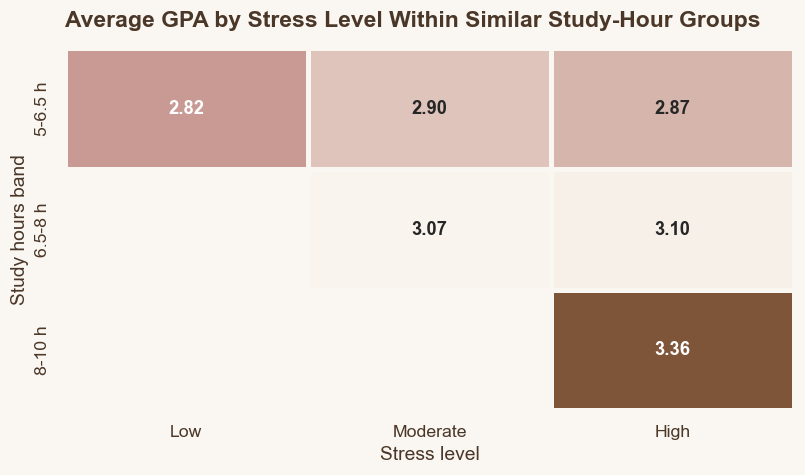

Stress_Level,Low,Moderate,High
Study_Band,,,
5-6.5 h,2.82,2.90,2.87
6.5-8 h,NaN,3.07,3.10
8-10 h,NaN,NaN,3.36


In [27]:
df["Study_Band"] = pd.cut(df["Study_Hours_Per_Day"], bins=[5, 6.5, 8, 10],
                          labels=["5-6.5 h", "6.5-8 h", "8-10 h"], include_lowest=True)
pivot = (df.pivot_table(index="Study_Band", columns="Stress_Level", values="GPA",
                        aggfunc="mean", observed=True)[STRESS_ORDER])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap=NUDE_DIVERGING, linewidths=2,
            linecolor=C["bg"], cbar=False, annot_kws={"fontsize": 12, "fontweight": "bold"}, ax=ax)
ax.grid(False)
finish(ax, "Average GPA by Stress Level Within Similar Study-Hour Groups", "Stress level",
       "Study hours band", "06_stress_gpa_controlled_for_study")
pivot.round(2)

## Interpretation: Does Stress Explain the Higher GPA?

High-stress students have the highest average GPA, which looks surprising. The table above compares GPA across stress levels within similar study-hour bands. In the 5-6.5 hour band, average GPA is 2.82 (low), 2.90 (moderate) and 2.87 (high stress). In the 6.5-8 hour band it is 3.07 (moderate) and 3.10 (high). GPA barely changes with stress once study time is similar.

This suggests study time, not stress, is what separates GPA across stress groups. Stress level is also closely tied to study time: no student in the 8-10 hour band reports low or moderate stress, which is why some cells are empty. These are associations, not proof of cause.

In [28]:
# We calculate correlation to measure the strength and direction
# of the relationship between sleep hours and GPA.

sleep_gpa_correlation = df["Sleep_Hours_Per_Day"].corr(df["GPA"])

# Display the correlation value.
print("Correlation between Sleep Hours and GPA:", sleep_gpa_correlation)

Correlation between Sleep Hours and GPA: -0.004278440948943779


## Interpretation: Sleep Hours and GPA

The correlation between Sleep Hours Per Day and GPA is approximately **-0.0043**.

This value is very close to zero, indicating that there is essentially **no linear relationship** between sleep hours and GPA in this dataset.

Unlike study hours, which showed a strong positive relationship with GPA, sleep hours do not show a meaningful linear association with GPA in this dataset.

This finding should not be interpreted as proof that sleep has no effect on academic performance. It only describes the relationship observed in this particular dataset.

In [29]:
# We calculate correlation to measure the strength and direction
# of the relationship between physical activity hours and GPA.

physical_gpa_correlation = df["Physical_Activity_Hours_Per_Day"].corr(df["GPA"])

# Display the correlation value.
print("Correlation between Physical Activity Hours and GPA:", physical_gpa_correlation)

Correlation between Physical Activity Hours and GPA: -0.3411524640099622


## Interpretation: Physical Activity and GPA

The correlation between Physical Activity Hours Per Day and GPA is **-0.3412**.

This indicates a moderate negative relationship in this dataset. Students who spend more time on physical activity tend to have lower GPAs.

However, this correlation does not prove that physical activity causes lower GPA. The result may be influenced by other lifestyle or academic factors, and it only describes the association observed in this dataset.

In [30]:
# We calculate correlation to measure the strength and direction
# of the relationship between social hours and GPA.

social_gpa_correlation = df["Social_Hours_Per_Day"].corr(df["GPA"])

# Display the correlation value.
print("Correlation between Social Hours and GPA:", social_gpa_correlation)

Correlation between Social Hours and GPA: -0.0856771404651373


## Interpretation: Social Hours and GPA

The correlation between Social Hours Per Day and GPA is **-0.0857**.

This value is very close to zero, indicating a **very weak negative relationship** between social hours and GPA in this dataset.

Therefore, social hours do not appear to have a meaningful linear association with GPA in this dataset.

This result describes an association only and does not prove that social activity causes changes in academic performance.

In [31]:
# We calculate correlation to measure the strength and direction
# of the relationship between extracurricular hours and GPA.

extracurricular_gpa_correlation = df["Extracurricular_Hours_Per_Day"].corr(df["GPA"])

# Display the correlation value.
print("Correlation between Extracurricular Hours and GPA:", extracurricular_gpa_correlation)

Correlation between Extracurricular Hours and GPA: -0.03217353173983064


## Interpretation: Extracurricular Hours and GPA

The correlation between Extracurricular Hours Per Day and GPA is **-0.0322**.

This value is very close to zero, indicating that there is an **extremely weak negative relationship** between extracurricular hours and GPA in this dataset.

Therefore, extracurricular hours do not appear to have a meaningful linear association with GPA in this dataset.

This result describes an association only and does not prove that extracurricular activities cause changes in academic performance.

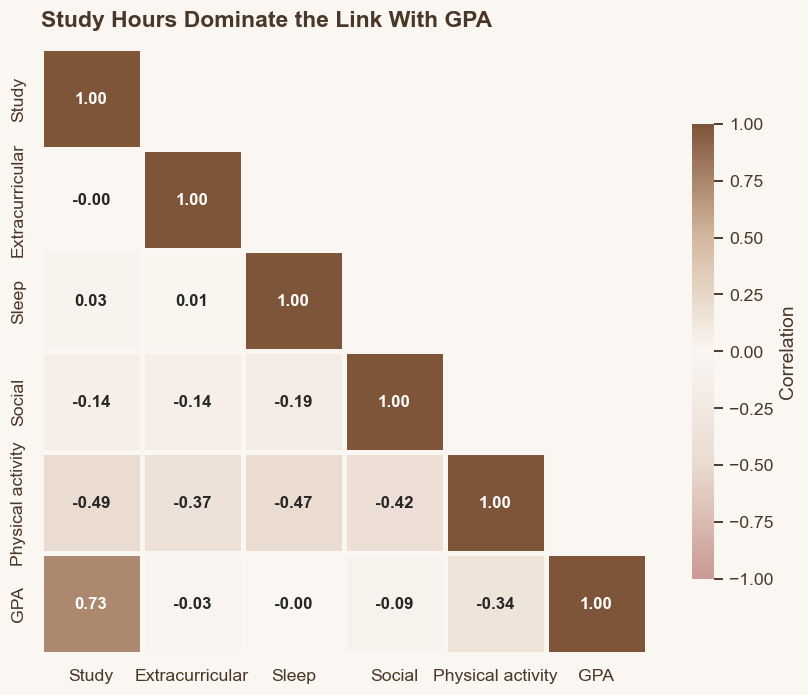

In [32]:
# Import libraries for correlation analysis and heatmap visualisation

labels = {"Study_Hours_Per_Day": "Study", "Extracurricular_Hours_Per_Day": "Extracurricular",
          "Sleep_Hours_Per_Day": "Sleep", "Social_Hours_Per_Day": "Social",
          "Physical_Activity_Hours_Per_Day": "Physical activity", "GPA": "GPA"}
corr = df[list(labels)].corr().rename(index=labels, columns=labels)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=NUDE_DIVERGING, center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor=C["bg"], square=True,
            annot_kws={"fontsize": 11, "fontweight": "bold"},
            cbar_kws={"shrink": 0.75, "label": "Correlation"}, ax=ax)
ax.grid(False)
finish(ax, "Study Hours Dominate the Link With GPA", name="07_correlation_heatmap")

## Interpretation: Correlation Heatmap

The correlation heatmap provides an overall view of the relationships between student lifestyle variables and GPA.

The strongest relationship with GPA is **Study Hours Per Day**, with a correlation of **0.7345**, indicating a strong positive association.

**Physical Activity Hours Per Day** has a moderate negative association with GPA (**-0.3412**), while Social Hours (**-0.0857**), Extracurricular Hours (**-0.0322**), and Sleep Hours (**-0.0043**) show weak or negligible linear associations with GPA.

The heatmap also shows negative relationships between several lifestyle variables. This is consistent with the earlier finding that the tracked lifestyle hours sum to a constant **24.0 hours** for every observation.

These correlations describe associations within this dataset and should not be interpreted as evidence of causation.

In [33]:
# We select the lifestyle variables that will be used to identify
# different patterns or groups of students.

lifestyle_features = df[
    [
        "Study_Hours_Per_Day",
        "Sleep_Hours_Per_Day",
        "Social_Hours_Per_Day",
        "Physical_Activity_Hours_Per_Day",
        "Extracurricular_Hours_Per_Day"
    ]
]

# Display the first five rows to check our selected variables.
lifestyle_features.head()

,Study_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,Extracurricular_Hours_Per_Day
0,6.9,8.7,2.8,1.8,3.8
1,5.3,8.0,4.2,3.0,3.5
2,5.1,9.2,1.2,4.6,3.9
3,6.5,7.2,1.7,6.5,2.1
4,8.1,6.5,2.2,6.6,0.6


In [34]:
# We standardize the lifestyle variables so that each variable
# has a comparable influence when we create student groups.

from sklearn.preprocessing import StandardScaler

# Create the scaler.
scaler = StandardScaler()

# Standardize the lifestyle data.
lifestyle_scaled = scaler.fit_transform(lifestyle_features)

# Display the first five standardized rows.
lifestyle_scaled[:5]

array([[-0.40448677,  0.82073377,  0.05654313, -1.00589562,  1.56624592],
       [-1.52845139,  0.34147317,  0.88588186, -0.52847018,  1.30663281],
       [-1.66894696,  1.16306277, -0.89127256,  0.10809708,  1.65278363],
       [-0.68547792, -0.20625322, -0.59508016,  0.86402069,  0.09510494],
       [ 0.4384867 , -0.68551382, -0.29888775,  0.90380615, -1.20296064]])

In [35]:
from sklearn.preprocessing import StandardScaler

lifestyle_features = df[
    [
        "Study_Hours_Per_Day",
        "Sleep_Hours_Per_Day",
        "Social_Hours_Per_Day",
        "Physical_Activity_Hours_Per_Day",
        "Extracurricular_Hours_Per_Day",
    ]
]

scaler = StandardScaler()
lifestyle_scaled = scaler.fit_transform(lifestyle_features)

lifestyle_scaled[:5]

array([[-0.40448677,  0.82073377,  0.05654313, -1.00589562,  1.56624592],
       [-1.52845139,  0.34147317,  0.88588186, -0.52847018,  1.30663281],
       [-1.66894696,  1.16306277, -0.89127256,  0.10809708,  1.65278363],
       [-0.68547792, -0.20625322, -0.59508016,  0.86402069,  0.09510494],
       [ 0.4384867 , -0.68551382, -0.29888775,  0.90380615, -1.20296064]])

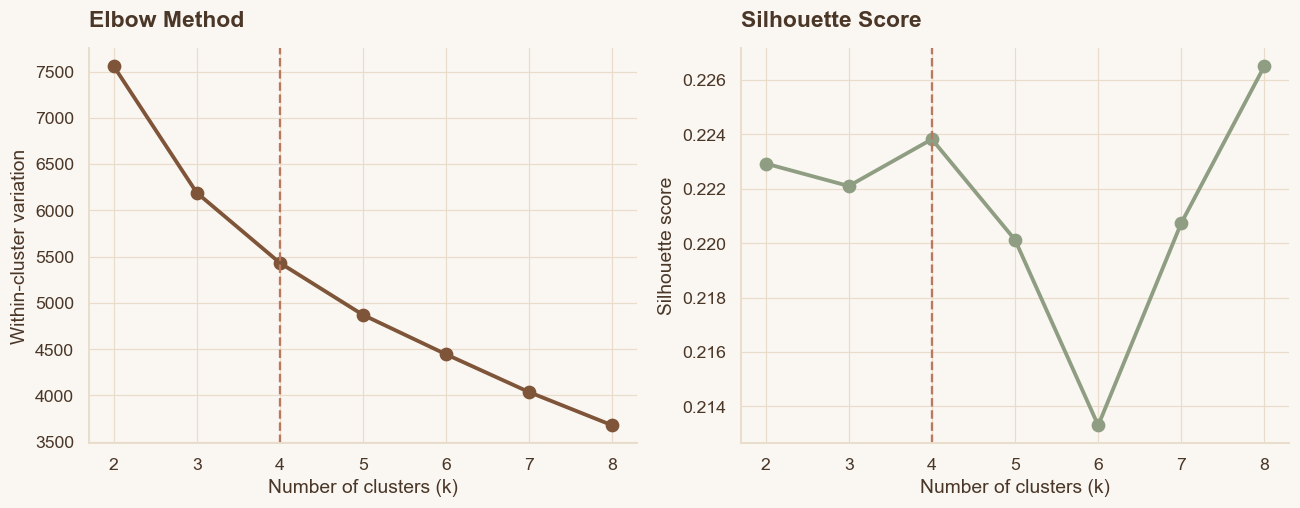

{2: np.float64(0.223), 3: np.float64(0.222), 4: np.float64(0.224), 5: np.float64(0.22), 6: np.float64(0.213), 7: np.float64(0.221), 8: np.float64(0.227)}


In [36]:
# We use the Elbow Method to find a suitable number of
# student lifestyle groups for our K-Means clustering.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = list(range(2, 9))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(lifestyle_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(lifestyle_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(ks, inertia, marker="o", color=C["mocha"], lw=2.5, ms=8)
axes[0].axvline(4, color=C["clay"], ls="--"); axes[0].set_title("Elbow Method", loc="left")
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("Within-cluster variation")
axes[1].plot(ks, sil, marker="o", color=C["sage"], lw=2.5, ms=8)
axes[1].axvline(4, color=C["clay"], ls="--"); axes[1].set_title("Silhouette Score", loc="left")
axes[1].set_xlabel("Number of clusters (k)"); axes[1].set_ylabel("Silhouette score")
plt.tight_layout(); plt.savefig("images/08_choosing_k.png", dpi=200, bbox_inches="tight"); plt.show()
print(dict(zip(ks, np.round(sil, 3))))


## Interpretation of the Elbow Method and Silhouette Score

The elbow plot shows within-cluster variation falling steadily as clusters are added, with a mild bend around 3 to 4 clusters and no sharp elbow. Silhouette scores are low and nearly flat across k = 2 to 8 (about 0.21 to 0.23), which indicates that the lifestyle groups overlap and are not sharply separated.

**4 clusters were selected** as a practical balance between model fit and interpretable student profiles. The clusters are best read as useful descriptive groupings rather than naturally separate segments.

In [37]:
# We use K-Means clustering to divide students into 4 groups
# based on their standardized lifestyle characteristics.

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign each student to one of the four clusters.
clusters = kmeans.fit_predict(lifestyle_scaled)

# Add the cluster assignment to the original dataset.
df["Lifestyle_Cluster"] = clusters

# Display the first five students and their assigned cluster.
df.head()

,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level,Study_Band,Lifestyle_Cluster
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate,6.5-8 h,0
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low,5-6.5 h,0
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low,5-6.5 h,0
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate,5-6.5 h,1
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High,8-10 h,1


In [38]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Lifestyle_Cluster"] = kmeans.fit_predict(lifestyle_scaled)

df[["Student_ID", "Lifestyle_Cluster"]].head()

,Student_ID,Lifestyle_Cluster
0,1,0
1,2,0
2,3,0
3,4,1
4,5,1


In [39]:
cluster_names = {0: "Rested Socialisers", 1: "Fitness-First", 2: "Focused Achievers",
                 3: "Study-Social Strivers"}
df["Cluster_Name"] = df["Lifestyle_Cluster"].map(cluster_names)
name_order = [cluster_names[i] for i in range(4)]
cluster_colors = dict(zip(name_order, CLUSTER_COLORS))

summary = (df.groupby("Cluster_Name").agg(
    Students=("GPA", "size"), Avg_GPA=("GPA", "mean"),
    Study=("Study_Hours_Per_Day", "mean"), Sleep=("Sleep_Hours_Per_Day", "mean"),
    Social=("Social_Hours_Per_Day", "mean"), Physical=("Physical_Activity_Hours_Per_Day", "mean"),
    Extracurricular=("Extracurricular_Hours_Per_Day", "mean")).round(2).loc[name_order])
summary

,Students,Avg_GPA,Study,Sleep,Social,Physical,Extracurricular
Cluster_Name,,,,,,,
Rested Socialisers,381,2.92,6.28,8.68,3.87,3.03,2.13
Fitness-First,588,2.99,6.61,6.75,1.68,7.40,1.54
Focused Achievers,533,3.30,8.71,8.61,1.50,2.76,2.42
Study-Social Strivers,498,3.21,8.08,6.30,4.30,3.37,1.95


### K-Means Clustering Results

The K-Means algorithm successfully grouped the **2,000 student records into four distinct lifestyle clusters** based on standardised lifestyle characteristics. Each student was assigned a cluster label (0–3), allowing us to examine different lifestyle patterns and compare their academic performance.

In [40]:
# We calculate the average lifestyle characteristics of students
# in each cluster so we can understand what each group represents.

cluster_profile = df.groupby("Lifestyle_Cluster")[
    [
        "Study_Hours_Per_Day",
        "Sleep_Hours_Per_Day",
        "Social_Hours_Per_Day",
        "Physical_Activity_Hours_Per_Day",
        "Extracurricular_Hours_Per_Day",
        "GPA"
    ]
].mean()

# Display the average characteristics of each cluster.
cluster_profile

,Study_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,Extracurricular_Hours_Per_Day,GPA
Lifestyle_Cluster,,,,,,
0,6.281890,8.681102,3.873753,3.029659,2.133596,2.924278
1,6.614116,6.754082,1.684524,7.404592,1.542687,2.994099
2,8.712008,8.608068,1.500938,2.762289,2.416698,3.298105
3,8.083534,6.296185,4.302610,3.365663,1.952008,3.211546


## Interpretation: Student Lifestyle Clusters

K-Means clustering identified four distinct student lifestyle profiles based on study, sleep, social, physical activity, and extracurricular hours.

- **Cluster 0 – Sleep & Social Balance:** Students in this group have the highest average sleep time (8.68 hours) and relatively high social time (3.87 hours), with an average study time of 6.28 hours.

- **Cluster 1 – Physically Active:** This group is characterized by the highest average physical activity (7.40 hours) and relatively lower social and extracurricular activity.

- **Cluster 2 – High Study & High Sleep:** Students in this group have the highest average study time (8.71 hours) and high sleep time (8.61 hours). This cluster also has the highest average GPA (3.30) among the four groups.

- **Cluster 3 – Study & Social:** Students in this group have relatively high study time (8.08 hours) and the highest social time (4.30 hours), along with the lowest average sleep time (6.30 hours).

These clusters represent different lifestyle patterns identified in the dataset. The differences are descriptive and do not establish that a particular lifestyle causes higher or lower academic performance.

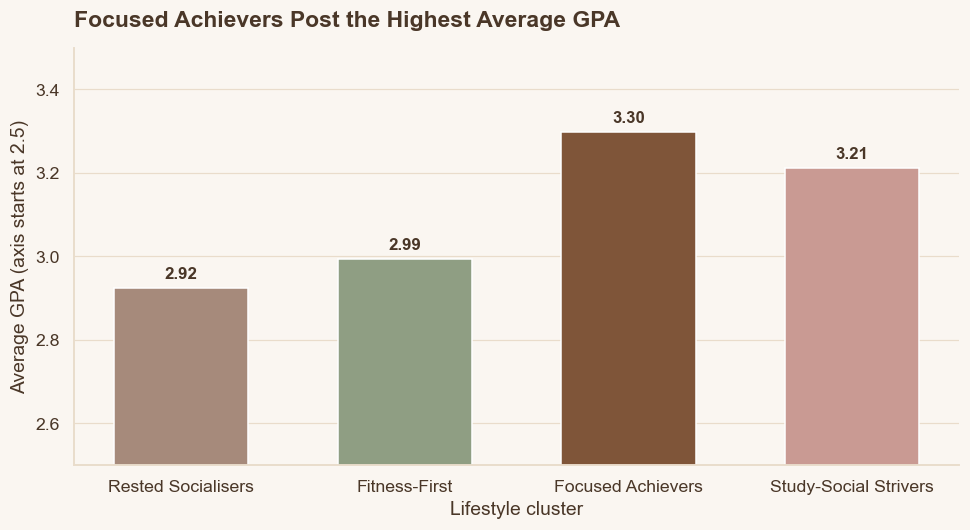

In [41]:
# We create a bar chart to compare the average GPA
# across the four student lifestyle clusters.
cl_gpa = df.groupby("Cluster_Name")["GPA"].mean().loc[name_order]
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(cl_gpa.index, cl_gpa.values, color=[cluster_colors[n] for n in cl_gpa.index], width=0.6)
ax.set_ylim(2.5, cl_gpa.max() + 0.2)
add_bar_labels(ax)
ax.grid(axis="x", visible=False)
finish(ax, "Focused Achievers Post the Highest Average GPA", "Lifestyle cluster",
       "Average GPA (axis starts at 2.5)", "09_gpa_by_cluster")


### Academic Performance Across Lifestyle Clusters

Cluster 2 records the highest average GPA of **3.30**, followed by Cluster 3 with **3.21**. Cluster 1 has an average GPA of **2.99**, while Cluster 0 records the lowest average of **2.92**.

These differences indicate that academic performance varies across the identified lifestyle groups. However, the results show associations rather than proving that a particular lifestyle pattern directly causes higher academic performance.

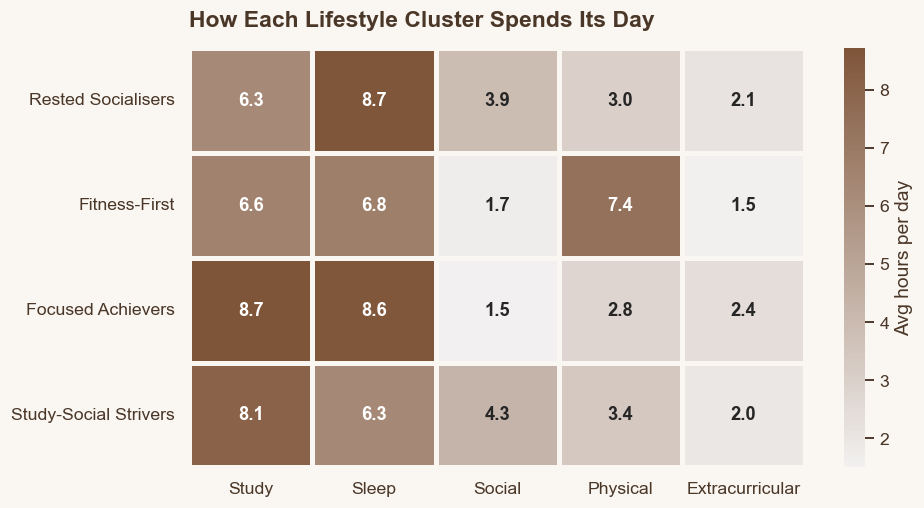

In [42]:
# We compare the average lifestyle characteristics of each cluster
# to understand what makes the student groups different.

cols = {"Study_Hours_Per_Day": "Study", "Sleep_Hours_Per_Day": "Sleep",
        "Social_Hours_Per_Day": "Social", "Physical_Activity_Hours_Per_Day": "Physical",
        "Extracurricular_Hours_Per_Day": "Extracurricular"}
prof = df.groupby("Cluster_Name")[list(cols)].mean().rename(columns=cols).loc[name_order]
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.heatmap(prof, annot=True, fmt=".1f", cmap=sns.light_palette(C["mocha"], as_cmap=True),
            linewidths=2, linecolor=C["bg"], cbar_kws={"label": "Avg hours per day"},
            annot_kws={"fontsize": 12, "fontweight": "bold"}, ax=ax)
ax.tick_params(axis="y", rotation=0); ax.grid(False)
finish(ax, "How Each Lifestyle Cluster Spends Its Day", "", "", "10_cluster_profiles")

## Interpretation of Lifestyle Characteristics Across Student Clusters

The line graph compares the average lifestyle characteristics of students across four lifestyle clusters.

- **Cluster 0:** Students have relatively high sleep hours (8.68 hours) and moderate study hours (6.28 hours). They also have relatively high social activity (3.87 hours).
- **Cluster 1:** Students show the highest physical activity (7.40 hours), with moderate study hours (6.61 hours) and lower social activity (1.68 hours).
- **Cluster 2:** Students have the highest study hours (8.71 hours) and high sleep hours (8.61 hours). Their social and physical activity hours are relatively lower.
- **Cluster 3:** Students have high study hours (8.08 hours) and the highest social activity (4.30 hours), while their sleep hours are relatively lower (6.30 hours).

### Overall Interpretation

The graph shows that the four clusters represent different student lifestyle patterns. The clusters differ mainly in terms of study, sleep, social, physical activity, and extracurricular hours. This indicates that the K-Means algorithm has successfully grouped students with similar lifestyle characteristics into distinct clusters.

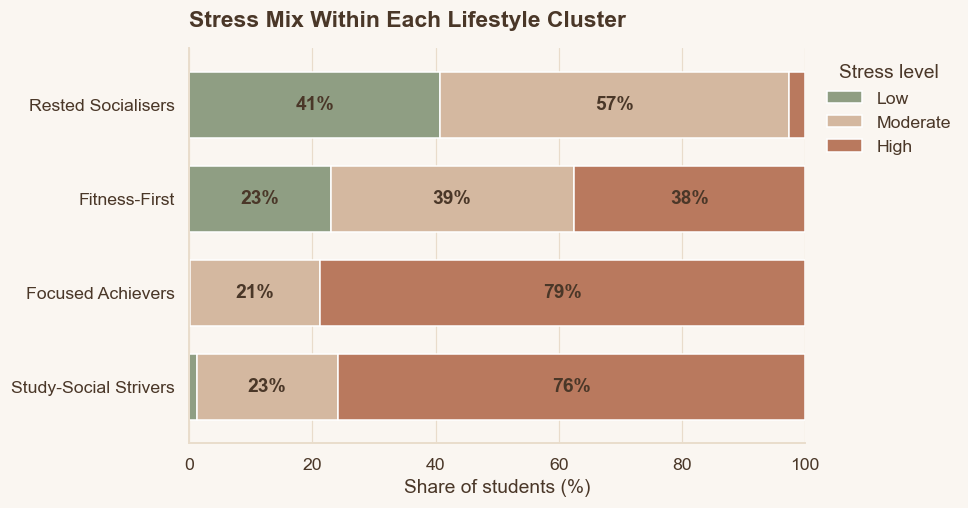

In [43]:
mix = (pd.crosstab(df["Cluster_Name"], df["Stress_Level"], normalize="index")
       .loc[name_order][STRESS_ORDER] * 100)
ax = mix.plot(kind="barh", stacked=True, figsize=(9, 4.8),
              color=[STRESS_COLORS[s] for s in STRESS_ORDER], width=0.7)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0f}%" if v > 6 else "" for v in c.datavalues],
                 label_type="center", color=C["cocoa"], fontweight="bold")
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.legend(title="Stress level", bbox_to_anchor=(1.01, 1), loc="upper left")
finish(ax, "Stress Mix Within Each Lifestyle Cluster", "Share of students (%)", "", "11_stress_by_cluster")

## Interpretation: Stress Mix Across Clusters

Stress levels differ sharply by cluster. "Focused Achievers" (79% high stress) and "Study-Social Strivers" (76% high stress) are dominated by high stress, consistent with their long study hours. "Rested Socialisers" report the lowest stress, with 41% low and almost none high. "Fitness-First" students are spread evenly across the three levels.

In [44]:
from scipy import stats

groups = [g["GPA"].values for _, g in df.groupby("Lifestyle_Cluster")]
f_stat, p_anova = stats.f_oneway(*groups)
h_stat, p_kw = stats.kruskal(*groups)
grand = df["GPA"].mean()
eta_sq = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((df["GPA"] - grand) ** 2).sum()
print(f"ANOVA (GPA across clusters): F = {f_stat:.2f}, p = {p_anova:.2e}")
print(f"Kruskal-Wallis: H = {h_stat:.2f}, p = {p_kw:.2e}")
print(f"Effect size (eta-squared) = {eta_sq:.3f}  (0.01 small, 0.06 medium, 0.14 large)")
rho, p_rho = stats.spearmanr(df["Study_Hours_Per_Day"], df["GPA"])
print(f"Spearman (Study vs GPA): rho = {rho:.3f}, p = {p_rho:.2e}")

ANOVA (GPA across clusters): F = 224.33, p = 2.09e-125
Kruskal-Wallis: H = 515.27, p = 2.34e-111
Effect size (eta-squared) = 0.252  (0.01 small, 0.06 medium, 0.14 large)
Spearman (Study vs GPA): rho = 0.743, p = 0.00e+00


## Interpretation: Statistical Tests

GPA differs significantly across the four clusters (ANOVA F = 224.33, p < 0.001; Kruskal-Wallis H = 515.27, p < 0.001). The effect size (eta-squared = 0.25) is large, meaning cluster membership accounts for about a quarter of the variation in GPA. Much of this comes from differences in study hours between clusters.

The Spearman rank correlation between study hours and GPA is 0.74, confirming the strong positive relationship is not driven by outliers or by assuming a straight-line relationship.


Test R-squared = 0.550 | Mean absolute error = 0.164 GPA points


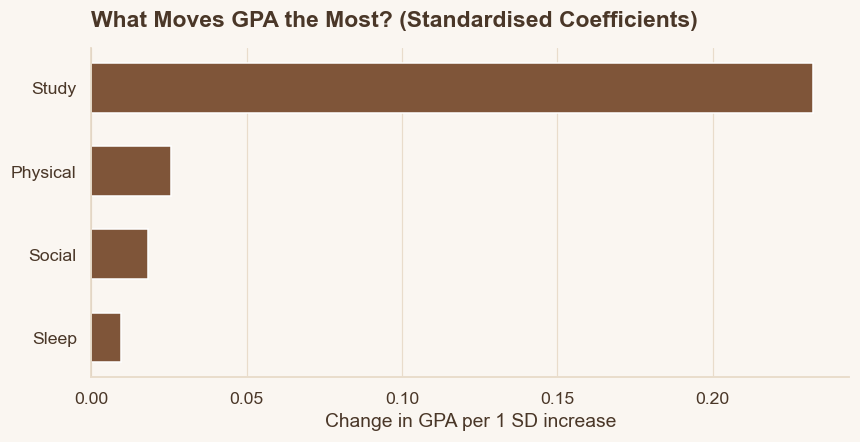

In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

# Extracurricular is left out on purpose: all five hours add up to 24,
# so using all five would make them perfectly dependent on each other.
feats = ["Study_Hours_Per_Day", "Sleep_Hours_Per_Day", "Social_Hours_Per_Day",
         "Physical_Activity_Hours_Per_Day"]
X_tr, X_te, y_tr, y_te = train_test_split(df[feats], df["GPA"], test_size=0.2, random_state=42)
sc = StandardScaler().fit(X_tr)
model = LinearRegression().fit(sc.transform(X_tr), y_tr)
pred = model.predict(sc.transform(X_te))
print(f"Test R-squared = {r2_score(y_te, pred):.3f} | Mean absolute error = {mean_absolute_error(y_te, pred):.3f} GPA points")

coef = pd.Series(model.coef_, index=["Study", "Sleep", "Social", "Physical"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(coef.index, coef.values, color=[C["mocha"] if v > 0 else C["rose"] for v in coef.values], height=0.6)
ax.axvline(0, color=C["cocoa"], lw=1); ax.grid(axis="y", visible=False)
finish(ax, "What Moves GPA the Most? (Standardised Coefficients)",
       "Change in GPA per 1 SD increase", "", "12_gpa_drivers")

## Interpretation: Predicting GPA

A linear regression using study, sleep, social and physical-activity hours reaches a test R² of 0.55, with an average prediction error of about 0.16 GPA points. Study hours have by far the largest standardised coefficient. Study hours alone correlate with GPA at r = 0.73 (R² ≈ 0.54), so the other lifestyle variables add very little.

Physical activity has a negative raw correlation with GPA but a small positive coefficient in the model. Its negative raw correlation reflects the fact that time spent on physical activity is time not spent studying. Extracurricular hours were excluded because the five time variables sum to 24 and would otherwise be perfectly dependent on each other.

## Key Findings

The analysis of the Student Lifestyle Dataset produced several important findings:

1. **Study Hours and GPA:** Study Hours Per Day showed the strongest positive correlation with GPA, with a correlation coefficient of **0.7345**. This indicates a strong positive association between study time and GPA in this dataset.

2. **Sleep and GPA:** Sleep Hours Per Day had a correlation of **-0.0043** with GPA, indicating almost no linear association between sleep duration and GPA in this dataset.

3. **Physical Activity and GPA:** Physical Activity Hours Per Day showed a moderate negative association with GPA, with a correlation coefficient of **-0.3412**.

4. **Social and Extracurricular Activities:** Social Hours Per Day (**-0.0857**) and Extracurricular Hours Per Day (**-0.0322**) showed very weak negative associations with GPA.

5. **Student Lifestyle Clusters:** K-Means clustering identified **four distinct lifestyle patterns** among the students based on their study, sleep, social, physical activity, and extracurricular hours.

6. **Cluster Academic Performance:** Cluster 2 had the highest average GPA (**3.30**) and was characterized by relatively high study hours (**8.71 hours**) and high sleep hours (**8.61 hours**).

These findings describe patterns and associations within the dataset and should not be interpreted as evidence of causation.

## Limitations of the Analysis

1. **Correlation does not imply causation.** All findings describe associations.
2. **Data appears constructed.** Every record's lifestyle hours sum to exactly 24.0 hours, no student studies or sleeps under 5 hours, and stress level is almost fully determined by study time. This suggests the data may be synthetic or heavily standardised. Results are best treated as a demonstration of analytical method, not as evidence about real student populations.
3. **Time is a closed system.** Because hours sum to 24, variables are not independent, which affects correlation and regression interpretation.
4. **Weak cluster structure.** Silhouette scores are about 0.22 for every k, so clusters overlap and the choice of four is a judgment call.
5. **Stress is a three-level category** and may be self-reported, giving limited detail.
6. **Single dataset with no time or demographic information.**

## Next Steps
- Validate the findings on real student survey data
- Add course load, demographic and wellbeing variables
- Compare the linear model with tree-based models
- Build an interactive dashboard (Power BI, Tableau or Streamlit)

## Conclusion

Study time is the strongest lifestyle correlate of GPA in this dataset, and it also explains why high-stress students show the highest GPA: they study more, and GPA hardly differs by stress once study time is similar. A regression using daily lifestyle hours explains about 55% of GPA variation, almost all of it through study hours. K-Means grouped students into four overlapping lifestyle profiles with significantly different GPAs, led by "Focused Achievers".

Because daily hours are capped at 24, the findings highlight how students trade time between activities rather than the effect of any single habit. All results are associations within one dataset that may be synthetic, and they provide a foundation for testing on real student data.